# FineWeb data caveats

This notebook downloads the same pre-tokenized FineWeb10B training shard used by the local alpha-sweep experiments and analyzes complete documents from its early-training token range. It flags *possible* truncation, compares document lengths, investigates small semantic clusters, and measures the singular-value spectrum of the document-embedding matrix. It does not reproduce the earlier Milestone 2 sample, its 29,204 flags, or its clusters.

The truncation flag is a deliberately simple punctuation heuristic, not evidence that a document was actually truncated. A small optional gradient probe uses a public pretrained language model, not the project's trained Muon model; its results are exploratory and cannot establish causation or reproduce the sweep. Embeddings use a limited prefix of each document. Cluster examples require human interpretation; the selected documents are an ordered early-training subset, not a random sample. The historical experiment did not record dataset checksums, so exact byte-for-byte identity with that run cannot be proven.


## Setup

Run the cells in order on Colab. The first code cell installs missing packages, then the notebook downloads one approximately 200 MB training shard and public models. On Intel Macs, use a Python 3.12 virtual environment; the setup cell checks compatible PyTorch and model-library versions. A T4 GPU can accelerate embedding and the optional gradient probe; CPU works but may take substantially longer. Outputs and downloaded files are temporary unless saved elsewhere. Review notebook outputs before uploading: examples may contain third-party web text.


In [ ]:
import importlib.util
import platform
import subprocess
import sys

required = {
    "huggingface_hub": "huggingface-hub",
    "sentence_transformers": "sentence-transformers",
    "transformers": "transformers",
    "sklearn": "scikit-learn",
    "tiktoken": "tiktoken",
    "dotenv": "python-dotenv",
}
if sys.platform == "darwin" and platform.machine() == "x86_64":
    required.update({
        "numpy": "numpy>=1.26,<2",
        "torch": "torch>=2.2,<2.3",
        "sentence_transformers": "sentence-transformers>=3,<4",
        "transformers": "transformers>=4.41,<4.45",
        "huggingface_hub": "huggingface-hub<1",
    })
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if sys.platform == "darwin" and platform.machine() == "x86_64":
    from importlib.metadata import PackageNotFoundError, version
    from packaging.requirements import Requirement
    for package in required.values():
        requirement = Requirement(package)
        if not requirement.specifier:
            continue
        try:
            installed = version(requirement.name)
        except PackageNotFoundError:
            if package not in missing:
                missing.append(package)
            continue
        if installed not in requirement.specifier and package not in missing:
            missing.append(package)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    print("Installed:", ", ".join(missing))
else:
    print("Required packages are already installed.")


Required packages are already installed.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET = "kjj0/fineweb10B-gpt2"
DATASET_REVISION = "889765ea1f903759787add96995d81171b632d0c"
TRAINING_SHARD = "fineweb_train_000001.bin"
SHARD_SHA256 = "771fa4a99b9fe0946ffb6e848b4ba5c6a9b0fe87860ebf03bc2c1c7e45f8178e"
EARLY_TRAIN_TOKENS = 100 * 512 * 1024  # First 100 steps of the sweep.
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
GRADIENT_MODEL = "distilbert/distilgpt2"
N_DOCUMENTS = 10000
N_CLUSTERS = 400
SEED = 42
EMBED_BATCH_SIZE = 64
RUN_GRADIENT_PROBE = False  # Optional: downloads a language model and performs backward passes.
GRADIENT_DOCS_PER_GROUP = 4
GRADIENT_MAX_TOKENS = 128


## Download and preparation

The sweep used `kjj0/fineweb10B-gpt2` training shards 1–33 in sorted order. This notebook downloads shard 1 and selects the first 10,000 nonempty documents fully bounded by GPT-2 end-of-text tokens within its first 52,428,800 tokens, corresponding to the first 100 training steps. It excludes any fragment at the shard or selection boundary; tokens are decoded for text analysis. The repository revision is pinned and the shard is verified against its published SHA-256, but the original run did not record either. A document is flagged if its last non-whitespace character is not sentence-ending punctuation (including closing quotes/brackets); this can catch lists or headings and miss actual truncation. Embeddings use only each document's prefix up to the embedding model's input limit.


In [ ]:
def load_fineweb_documents(dataset_name, revision, shard_name, expected_sha256, count, token_limit):
    """Download the training shard and decode bounded, complete documents in order."""
    import hashlib
    import tiktoken
    from huggingface_hub import hf_hub_download

    if count <= 0 or token_limit <= 0:
        raise ValueError("Document count and token limit must be positive.")
    shard_path = Path(hf_hub_download(repo_id=dataset_name, filename=shard_name,
                                      repo_type="dataset", revision=revision))
    digest = hashlib.sha256()
    with shard_path.open("rb") as handle:
        header_bytes = handle.read(256 * 4)
        if len(header_bytes) != 256 * 4:
            raise ValueError(f"Invalid FineWeb token-shard header: {shard_path}")
        header = np.frombuffer(header_bytes, dtype=np.int32)
        if header[0] != 20240520 or header[1] != 1 or header[2] <= 0:
            raise ValueError(f"Invalid FineWeb token-shard header: {shard_path}")
        token_count = int(header[2])
        if shard_path.stat().st_size != 256 * 4 + 2 * token_count:
            raise ValueError("Token-shard file size does not match its header.")
        handle.seek(0)
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    if digest.hexdigest() != expected_sha256:
        raise ValueError(f"Training shard SHA-256 mismatch: {digest.hexdigest()}")
    if token_limit > token_count:
        raise ValueError("The early-training token limit exceeds the training shard.")
    tokens = np.memmap(shard_path, dtype=np.uint16, mode="r", offset=256 * 4, shape=(token_count,))
    tokenizer = tiktoken.get_encoding("gpt2")
    boundaries = np.flatnonzero(tokens[:token_limit] == tokenizer.eot_token)
    rows = []
    for start, end in zip(boundaries[:-1], boundaries[1:]):
        token_ids = tokens[int(start) + 1:int(end)].astype(np.int32).tolist()
        text = tokenizer.decode(token_ids, errors="strict")
        if text.strip():
            rows.append({"doc_id": f"{shard_name}:{start}", "text": text,
                         "token_count": len(token_ids), "start_token": int(start)})
        if len(rows) == count:
            break
    if len(rows) != count:
        raise RuntimeError(f"Only {len(rows)} complete nonempty documents found in the token range; requested {count}.")
    return pd.DataFrame(rows), {"revision": revision, "sha256": digest.hexdigest(),
                               "shard_tokens": token_count, "token_limit": token_limit}


def prepare_documents(documents):
    """Preserve shard-token lengths and mark possible truncation by punctuation."""
    import re
    frame = documents.copy().reset_index(drop=True)
    if frame.empty or frame["text"].isna().any() or (frame["token_count"] <= 0).any():
        raise ValueError("Documents must contain nonempty text and positive shard-token counts.")
    frame["is_truncated"] = ~frame["text"].map(
        lambda text: bool(re.search(r'[.!?][\"\'\)\]\}]*\s*$', text))
    )
    return frame


def load_embedding_model(model_name):
    """Load a pinned public sentence embedding model and select CPU or CUDA."""
    import torch
    from huggingface_hub import HfApi
    from sentence_transformers import SentenceTransformer

    revision = HfApi().model_info(model_name).sha
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = SentenceTransformer(model_name, revision=revision, device=device)
    return model, revision, device


def prepare_document_embeddings(documents, model, batch_size):
    """Embed document prefixes and return one normalized vector per document."""
    vectors = model.encode(
        documents["text"].tolist(), batch_size=batch_size, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True,
    )
    vectors = np.asarray(vectors, dtype=np.float32)
    if vectors.ndim != 2 or vectors.shape[0] != len(documents) or not np.isfinite(vectors).all():
        raise ValueError("The embedding model returned invalid document vectors.")
    return vectors


def prepare_clusters(documents, vectors, count, seed):
    """Assign document vectors to deterministic mini-batch k-means clusters."""
    from sklearn.cluster import MiniBatchKMeans

    if not 2 <= count <= len(documents):
        raise ValueError("Cluster count must be between 2 and the number of documents.")
    model = MiniBatchKMeans(n_clusters=count, random_state=seed, n_init=3, batch_size=2048)
    labels = model.fit_predict(vectors)
    result = documents.copy()
    result["cluster_id"] = labels
    return result


## Truncation and length

Compare heuristic flags and length distributions; flagged does not mean confirmed truncated. The project's training loader uses fixed-length token windows, so document lengths do not directly equal model context lengths. The optional gradient probe below supplies only a small model- and layer-specific diagnostic.


In [ ]:
def analyze_truncation_lengths(documents):
    """Summarize token lengths separately for flagged and unflagged documents."""
    return documents.groupby("is_truncated")["token_count"].agg(
        count="size", mean="mean", median="median",
        p10=lambda values: values.quantile(0.1), p90=lambda values: values.quantile(0.9),
    )


def plot_truncation_lengths(documents):
    """Plot the length distribution for each heuristic group."""
    fig, ax = plt.subplots(figsize=(8, 4))
    for flagged, label in [(False, "Not flagged"), (True, "Possibly truncated")]:
        values = documents.loc[documents["is_truncated"] == flagged, "token_count"]
        if len(values):
            ax.hist(np.log10(values + 1), bins=40, density=True, alpha=0.5, label=label)
    ax.set_xlabel("log10(GPT-2 token count + 1)")
    ax.set_ylabel("Density")
    ax.legend()
    fig.tight_layout()
    return fig


## Small cluster diagnostics

“Small” means the lowest size decile among clusters in this new sample, not the previous study's size threshold. Compare within-cluster cosine cohesion with nearest-centroid similarity and inspect examples; these are screening diagnostics, not automatic judgments that a cluster is meaningful or noisy. Cluster labels are arbitrary.


In [ ]:
def analyze_small_clusters(documents, vectors):
    """Summarize cluster sizes, cohesion, and nearest-other-centroid similarity."""
    labels = documents["cluster_id"].to_numpy()
    clusters = np.unique(labels)
    centroids, rows = [], []
    for cluster in clusters:
        members = vectors[labels == cluster]
        center = members.mean(axis=0)
        norm = np.linalg.norm(center)
        if norm == 0:
            raise ValueError(f"Cluster {cluster} has a zero centroid.")
        center = center / norm
        centroids.append(center)
        rows.append({
            "cluster_id": cluster, "document_count": len(members),
            "mean_within_cosine": float(np.mean(members @ center)),
            "flagged_fraction": float(documents.loc[labels == cluster, "is_truncated"].mean()),
        })
    similarities = np.asarray(centroids) @ np.asarray(centroids).T
    np.fill_diagonal(similarities, -np.inf)
    summary = pd.DataFrame(rows)
    summary["nearest_centroid_cosine"] = similarities.max(axis=1)
    cutoff = summary["document_count"].quantile(0.1)
    summary["is_small"] = summary["document_count"] <= cutoff
    return summary.sort_values("document_count", kind="stable").reset_index(drop=True)


def select_small_cluster_examples(documents, summary, cluster_count=10, examples_per_cluster=3):
    """Return examples from the smallest clusters for manual review."""
    selected = summary.loc[summary["is_small"], "cluster_id"].head(cluster_count)
    subset = documents[documents["cluster_id"].isin(selected)]
    return subset.groupby("cluster_id", sort=True).head(examples_per_cluster)[
        ["cluster_id", "doc_id", "text"]
    ]


def plot_cluster_diagnostics(summary):
    """Plot cluster size and vector-based cohesion/separation proxies."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(summary["document_count"], bins=30)
    axes[0].set(xlabel="Documents per cluster", ylabel="Clusters", title="Cluster sizes")
    for small, label in [(False, "Other"), (True, "Small")]:
        subset = summary[summary["is_small"] == small]
        axes[1].scatter(subset["mean_within_cosine"], subset["nearest_centroid_cosine"],
                        s=20, alpha=0.7, label=label)
    axes[1].set(xlabel="Mean within-cluster cosine", ylabel="Nearest-centroid cosine",
                title="Embedding-space diagnostics")
    axes[1].legend()
    fig.tight_layout()
    return fig


## Document-embedding spectrum

The matrix has one row per sampled document and one column per embedding dimension. We report the singular values, numerical rank, condition number, and entropy effective rank using squared singular values as energy weights. This is the geometry of the **document representations**, not the GPT token-embedding weights or optimizer gradients.


In [ ]:
def analyze_embedding_spectrum(vectors):
    """Measure the singular spectrum and energy-weighted effective rank."""
    matrix = np.asarray(vectors, dtype=np.float64)
    if matrix.ndim != 2 or min(matrix.shape) == 0 or not np.isfinite(matrix).all():
        raise ValueError("Embeddings must be a nonempty finite 2D matrix.")
    singular = np.linalg.svd(matrix, compute_uv=False, full_matrices=False)
    tolerance = np.finfo(matrix.dtype).eps * max(matrix.shape) * singular[0]
    rank = int(np.sum(singular > tolerance))
    if singular[0] == 0:
        effective_rank, condition = 0.0, float("inf")
    else:
        positive = singular[singular > tolerance]
        weights = positive ** 2 / np.sum(positive ** 2)
        effective_rank = float(np.exp(-np.sum(weights * np.log(weights))))
        condition = float(singular[0] / singular[-1]) if rank == len(singular) else float("inf")
    return {"shape": matrix.shape, "singular_values": singular, "numerical_rank": rank,
            "effective_rank": effective_rank, "condition_number": condition, "rank_tolerance": tolerance}


def plot_embedding_spectrum(spectrum):
    """Plot singular values and cumulative squared-spectrum energy."""
    singular = spectrum["singular_values"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].semilogy(np.arange(1, len(singular) + 1), singular)
    axes[0].set(xlabel="Singular-value index", ylabel="Singular value", title="Document-embedding spectrum")
    energy = np.cumsum(singular ** 2)
    if energy[-1] > 0:
        axes[1].plot(np.arange(1, len(singular) + 1), energy / energy[-1])
    axes[1].set(xlabel="Leading singular values", ylabel="Cumulative energy",
                title=f"Effective rank: {spectrum['effective_rank']:.1f}")
    fig.tight_layout()
    return fig


## Optional gradient probe

Set `RUN_GRADIENT_PROBE = True` to download pretrained DistilGPT-2 and calculate per-document gradient singular-value statistics for its first attention query projection. It uses a fixed maximum token prefix, up to four documents per heuristic group, and reports actual used lengths. This small, non-Muon proxy is not a substitute for matched gradient measurements from the project's trained model, and unbalanced length distributions or punctuation heuristics can confound the comparison.


In [ ]:
def analyze_gradient_spectra(documents, model_name, per_group, max_tokens, seed):
    """Probe query-projection gradients on a small sample of each heuristic group."""
    import torch
    from huggingface_hub import HfApi
    from transformers import AutoModelForCausalLM, AutoTokenizer

    if per_group < 1 or max_tokens < 2:
        raise ValueError("Gradient probe requires a positive sample size and at least two tokens.")
    if documents["is_truncated"].nunique() != 2:
        raise ValueError("Gradient probe requires both flagged and unflagged documents.")
    revision = HfApi().model_info(model_name).sha
    tokenizer = AutoTokenizer.from_pretrained(model_name, revision=revision)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = AutoModelForCausalLM.from_pretrained(model_name, revision=revision).to(device)
    model.eval()
    parameter = model.transformer.h[0].attn.c_attn.weight
    width = model.config.n_embd
    selected = documents.groupby("is_truncated", group_keys=False).sample(
        n=per_group, random_state=seed
    )
    records = []
    for row in selected.itertuples(index=False):
        encoded = tokenizer(row.text, return_tensors="pt", truncation=True, max_length=max_tokens)
        ids = encoded["input_ids"].to(device)
        if ids.shape[1] < 2:
            raise ValueError(f"Document {row.doc_id} has fewer than two probe tokens.")
        model.zero_grad(set_to_none=True)
        model(input_ids=ids, labels=ids).loss.backward()
        gradient = parameter.grad[:, :width].detach().float()
        singular = torch.linalg.svdvals(gradient).cpu().numpy()
        positive = singular[singular > np.finfo(np.float32).eps * max(gradient.shape) * singular[0]]
        if not len(positive):
            raise ValueError(f"Zero or numerically singular gradient for document {row.doc_id}.")
        weights = positive ** 2 / np.sum(positive ** 2)
        records.append({
            "doc_id": row.doc_id, "is_truncated": row.is_truncated,
            "original_token_count": row.token_count, "probe_tokens": ids.shape[1],
            "gradient_effective_rank": float(np.exp(-np.sum(weights * np.log(weights)))),
            "gradient_condition_nonzero": float(positive[0] / positive[-1]),
            "gradient_numerical_rank": len(positive),
        })
    return pd.DataFrame(records), revision, device


def plot_gradient_spectra(metrics):
    """Plot per-document gradient effective ranks and numerical condition numbers."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for index, (flagged, group) in enumerate(metrics.groupby("is_truncated")):
        axes[0].scatter(np.full(len(group), index), group["gradient_effective_rank"], label=str(flagged))
        axes[1].scatter(np.full(len(group), index), group["gradient_condition_nonzero"], label=str(flagged))
    for ax in axes:
        ax.set_xticks([0, 1], ["Not flagged", "Flagged"])
    axes[0].set_ylabel("Gradient effective rank")
    axes[1].set_ylabel("Condition number (numerically nonzero spectrum)")
    axes[1].set_yscale("log")
    fig.tight_layout()
    return fig


## Run the analysis

Data and model downloads require internet. This may take time, especially on CPU; progress bars show embedding progress. The notebook prints source revisions and settings, then tables and plots. No inputs need to be uploaded.


fineweb_train_000001.bin: reconstructing file:   0%|          |  0.00B /  200MB            

fineweb_train_000001.bin: downloading bytes:           |  0.00B            

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (8 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Dataset: kjj0/fineweb10B-gpt2@889765ea1f903759787add96995d81171b632d0c; shard=fineweb_train_000001.bin; sha256=771fa4a99b9fe0946ffb6e848b4ba5c6a9b0fe87860ebf03bc2c1c7e45f8178e; first_tokens=52,428,800; documents=10,000; last_document_offset=6,870,816
Embedding model: sentence-transformers/all-MiniLM-L6-v2@1110a243fdf4706b3f48f1d95db1a4f5529b4d41; device=cpu; max_input_tokens=256; clusters=400
Truncation heuristic and lengths:


,count,mean,median,p10,p90
is_truncated,,,,,
False,6931,692.418121,408.0,127.0,1345.0
True,3069,672.435321,376.0,114.8,1337.4


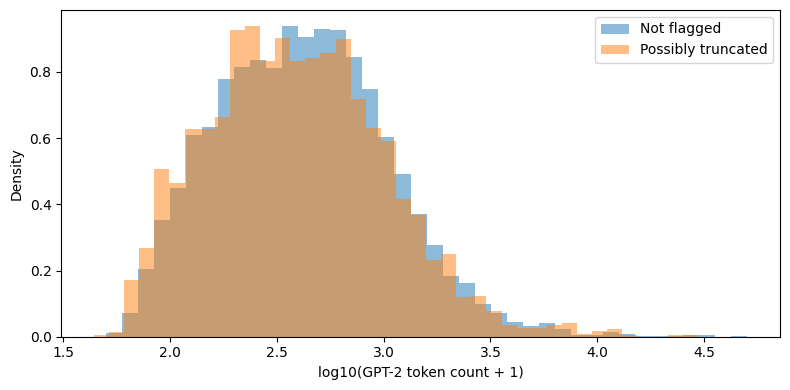

Smallest clusters:


,cluster_id,document_count,mean_within_cosine,flagged_fraction,nearest_centroid_cosine,is_small
0,5,1,1.0,0.0,0.635008,True
1,6,1,1.0,1.0,0.544048,True
2,8,1,1.0,0.0,0.572713,True
3,10,1,1.0,0.0,0.567036,True
4,18,1,1.0,0.0,0.468607,True
5,26,1,1.0,0.0,0.498609,True
6,27,1,1.0,0.0,0.505230,True
7,36,1,1.0,1.0,0.349062,True
8,44,1,1.0,0.0,0.579316,True
9,53,1,1.0,1.0,0.637909,True


Cluster examples for human review:


,cluster_id,doc_id,text
837,27,fineweb_train_000001.bin:581700,Kingdom celebrations this new year's eve kingd...
2915,53,fineweb_train_000001.bin:1959970,Our Advisory Practice Group acts on behalf of ...
5380,44,fineweb_train_000001.bin:3667663,Welcome to the brand new Bristol Manor Farm FC...
6112,36,fineweb_train_000001.bin:4242637,Skip to content.\nHome > University Communicat...
7046,5,fineweb_train_000001.bin:4853184,Comentarios de la gente - Escribir un comentar...
7473,6,fineweb_train_000001.bin:5147028,The Ottawa Hospital has entered into a partner...
7874,8,fineweb_train_000001.bin:5439969,Warning! Last night I checked my e-mail and ha...
7891,10,fineweb_train_000001.bin:5462805,Mario Gabelli is one of the best value investo...
9416,18,fineweb_train_000001.bin:6480084,"Mark Gagnon, associate dean of student service..."
9609,26,fineweb_train_000001.bin:6609631,Consider the difference between 2:29 minutes a...


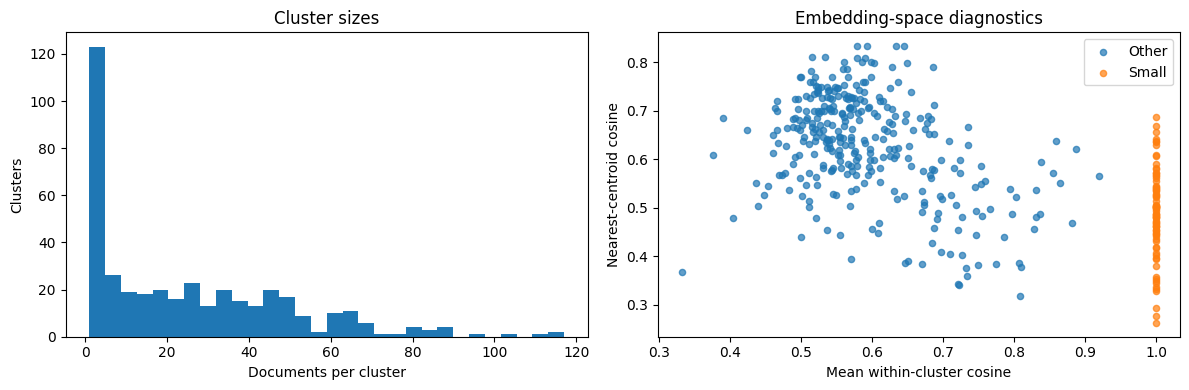

,shape,numerical_rank,effective_rank,condition_number,rank_tolerance
0,"(10000, 384)",382,182.354173,inf,5.684725e-11


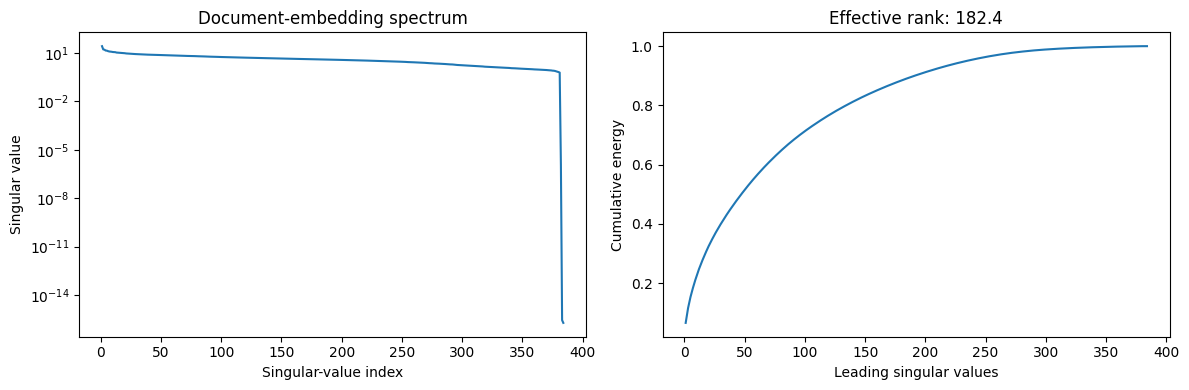

In [ ]:
raw_documents, shard_info = load_fineweb_documents(
    DATASET, DATASET_REVISION, TRAINING_SHARD, SHARD_SHA256, N_DOCUMENTS, EARLY_TRAIN_TOKENS
)
documents = prepare_documents(raw_documents)
embedding_model, embedding_revision, device = load_embedding_model(EMBEDDING_MODEL)
vectors = prepare_document_embeddings(documents, embedding_model, EMBED_BATCH_SIZE)
documents = prepare_clusters(documents, vectors, N_CLUSTERS, SEED)
print(f"Dataset: {DATASET}@{shard_info['revision']}; shard={TRAINING_SHARD}; "
      f"sha256={shard_info['sha256']}; first_tokens={shard_info['token_limit']:,}; "
      f"documents={len(documents):,}; last_document_offset={documents['start_token'].iloc[-1]:,}")
print(f"Embedding model: {EMBEDDING_MODEL}@{embedding_revision}; device={device}; "
      f"max_input_tokens={embedding_model.max_seq_length}; clusters={N_CLUSTERS}")

print("Truncation heuristic and lengths:")
display(analyze_truncation_lengths(documents))
plot_truncation_lengths(documents)
plt.show()

clusters = analyze_small_clusters(documents, vectors)
print("Smallest clusters:")
display(clusters.head(20))
print("Cluster examples for human review:")
display(select_small_cluster_examples(documents, clusters))
plot_cluster_diagnostics(clusters)
plt.show()

spectrum = analyze_embedding_spectrum(vectors)
display(pd.DataFrame([{key: value for key, value in spectrum.items() if key != "singular_values"}]))
plot_embedding_spectrum(spectrum)
plt.show()


In [ ]:
if RUN_GRADIENT_PROBE:
    gradient_metrics, gradient_revision, gradient_device = analyze_gradient_spectra(
        documents, GRADIENT_MODEL, GRADIENT_DOCS_PER_GROUP, GRADIENT_MAX_TOKENS, SEED
    )
    print(f"Gradient model: {GRADIENT_MODEL}@{gradient_revision}; device={gradient_device}")
    display(gradient_metrics)
    display(gradient_metrics.groupby("is_truncated")[
        ["probe_tokens", "gradient_effective_rank", "gradient_condition_nonzero"]
    ].agg(["count", "median"]))
    plot_gradient_spectra(gradient_metrics)
    plt.show()
else:
    print("Gradient probe not run. Set RUN_GRADIENT_PROBE=True to measure this proxy.")


Gradient probe not run. Set RUN_GRADIENT_PROBE=True to measure this proxy.


## Optional: publish this notebook to GitHub

The function below uploads only this notebook to `jhshi1879/condition-number-adaptive-muon` on the `main` branch. It requires a GitHub token with repository contents write permission, asks for explicit confirmation, reads the existing file SHA before updating, and verifies the uploaded bytes. It first checks the `GITHUB_TOKEN` environment variable; on macOS, if that is unset, it reads `GITHUB_TOKEN` from `.env` next to the notebook without shell expansion. Otherwise it prompts securely. In Colab, pass the path where you saved this notebook and use Colab Secrets or the prompt. Never save tokens or sensitive outputs in the notebook.


In [ ]:
# def upload_notebook_to_github(
#     notebook_path="caveats.ipynb",
#     repository="jhshi1879/condition-number-adaptive-muon",
#     branch="main",
#     remote_path="caveats.ipynb",
# ):
#     """Upload this notebook to the selected GitHub repository after confirmation."""
#     import base64
#     import json
#     import os
#     import sys
#     from getpass import getpass
#     from urllib.error import HTTPError
#     from urllib.parse import quote
#     from urllib.request import Request, urlopen

#     notebook_path = Path(notebook_path)
#     if not notebook_path.is_file():
#         raise FileNotFoundError(
#             f"Notebook file not found: {notebook_path}. In Colab, pass its Drive or /content path."
#         )
#     if repository.count("/") != 1 or any(part in {"", ".", ".."} for part in repository.split("/")):
#         raise ValueError("repository must have the form owner/repository.")
#     if not remote_path or remote_path.startswith("/") or ".." in Path(remote_path).parts:
#         raise ValueError("remote_path must be a repository-relative file path.")

#     content = notebook_path.read_bytes()
#     token = os.environ.get("GITHUB_TOKEN")
#     if not token and sys.platform == "darwin":
#         env_path = notebook_path.resolve().parent / ".env"
#         if env_path.is_file():
#             from dotenv import dotenv_values
#             token = dotenv_values(env_path, interpolate=False).get("GITHUB_TOKEN")
#     if not token:
#         token = getpass("GitHub token (contents:write; input is hidden): ")
#     if not token:
#         raise ValueError("A GitHub token is required.")
#     confirmation = input(
#         f"Upload {notebook_path} to {repository}/{remote_path} on branch {branch}? Type UPLOAD to continue: "
#     )
#     if confirmation != "UPLOAD":
#         print("Upload cancelled; no GitHub request was made.")
#         return None

#     api_url = f"https://api.github.com/repos/{repository}/contents/{quote(remote_path, safe='/')}"
#     headers = {
#         "Accept": "application/vnd.github+json",
#         "Authorization": f"Bearer {token}",
#         "X-GitHub-Api-Version": "2022-11-28",
#         "User-Agent": "condition-number-adaptive-muon-caveats-notebook",
#     }

#     def request_json(request):
#         with urlopen(request, timeout=30) as response:
#             return json.loads(response.read().decode("utf-8"))

#     read_url = f"{api_url}?ref={quote(branch, safe='')}"
#     existing = None
#     try:
#         existing = request_json(Request(read_url, headers=headers, method="GET"))
#     except HTTPError as exc:
#         if exc.code != 404:
#             raise RuntimeError(f"GitHub read failed with HTTP {exc.code}.") from exc

#     payload = {
#         "message": "Add/update caveats analysis notebook",
#         "content": base64.b64encode(content).decode("ascii"),
#         "branch": branch,
#     }
#     if existing is not None:
#         if "sha" not in existing:
#             raise RuntimeError("GitHub returned an existing file without its SHA; refusing to overwrite.")
#         payload["sha"] = existing["sha"]
#     update_request = Request(
#         api_url,
#         data=json.dumps(payload).encode("utf-8"),
#         headers={**headers, "Content-Type": "application/json"},
#         method="PUT",
#     )
#     try:
#         published = request_json(update_request)
#     except HTTPError as exc:
#         raise RuntimeError(f"GitHub upload failed with HTTP {exc.code}.") from exc

#     try:
#         verified = request_json(Request(read_url, headers=headers, method="GET"))
#     except HTTPError as exc:
#         raise RuntimeError(f"Upload returned, but GitHub read-back failed with HTTP {exc.code}.") from exc
#     remote_content = base64.b64decode(verified.get("content", ""))
#     if remote_content != content:
#         raise RuntimeError("GitHub read-back did not match the local notebook bytes.")

#     commit_url = published.get("commit", {}).get("html_url")
#     print(f"Verified upload: {commit_url or api_url}")
#     return {"repository": repository, "branch": branch, "path": remote_path, "commit_url": commit_url}


In [ ]:
def upload_notebook_to_github():
    import base64, hashlib, json, requests
    from google.colab import _message, userdata

    if not all(name in globals() for name in ("documents", "clusters", "spectrum")):
        raise RuntimeError("Run the analysis cells before uploading.")

    reply = _message.blocking_request("get_ipynb", timeout_sec=30)
    notebook = reply.get("ipynb") if isinstance(reply, dict) else None
    if not isinstance(notebook, dict) or not isinstance(notebook.get("cells"), list):
        raise RuntimeError("Could not read the open Colab notebook.")

    content = json.dumps(notebook, ensure_ascii=False).encode("utf-8")
    token = userdata.get("GITHUB_TOKEN")
    if not token:
        raise RuntimeError("Enable notebook access to the GITHUB_TOKEN Colab secret.")
    if token.encode("utf-8") in content:
        raise RuntimeError("Token appears in notebook contents; upload blocked.")

    url = "https://api.github.com/repos/jhshi1879/condition-number-adaptive-muon/contents/caveats.ipynb"
    headers = {
        "Authorization": f"Bearer {token}",
        "Accept": "application/vnd.github+json",
        "X-GitHub-Api-Version": "2022-11-28",
    }

    current = requests.get(url, headers=headers, params={"ref": "main"}, timeout=30)
    if current.status_code != 404:
        current.raise_for_status()

    payload = {
        "message": "Update caveats notebook\n\nCo-authored-by: Copilot <223556219+Copilot@users.noreply.github.com>",
        "content": base64.b64encode(content).decode("ascii"),
        "branch": "main",
    }
    if current.status_code == 200:
        payload["sha"] = current.json()["sha"]

    result = requests.put(url, headers=headers, json=payload, timeout=60)
    result.raise_for_status()

    check = requests.get(url, headers=headers, params={"ref": "main"}, timeout=30)
    check.raise_for_status()
    expected = hashlib.sha1(f"blob {len(content)}\0".encode("ascii") + content).hexdigest()
    if check.json().get("sha") != expected:
        raise RuntimeError("Upload returned, but GitHub verification failed.")

    print("Uploaded and verified:", result.json()["commit"]["html_url"])


upload_notebook_to_github()